# Training curves

Reads `log/log.txt` (lines of the form `<step> <train|val|hella> <value>`) written by `train_gpt2.py` and plots:
1. train / val loss
2. HellaSwag accuracy vs. OpenAI GPT-2 baselines

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("log/log.txt", sep=r"\s+", names=["step", "kind", "value"])
train = df[df.kind == "train"].set_index("step")["value"]
val = df[df.kind == "val"].set_index("step")["value"]
hella = df[df.kind == "hella"].set_index("step")["value"]
print(f"last step: {df.step.max()} | train points: {len(train)} | val points: {len(val)} | hella points: {len(hella)}")
print(f"latest val loss: {val.iloc[-1]:.4f} | latest hellaswag: {hella.iloc[-1]:.4f} | best hellaswag: {hella.max():.4f} @ step {hella.idxmax()}")

last step: 93858 | train points: 93859 | val points: 377 | hella points: 377
latest val loss: 3.0793 | latest hellaswag: 0.3099 | best hellaswag: 0.3102 @ step 93750


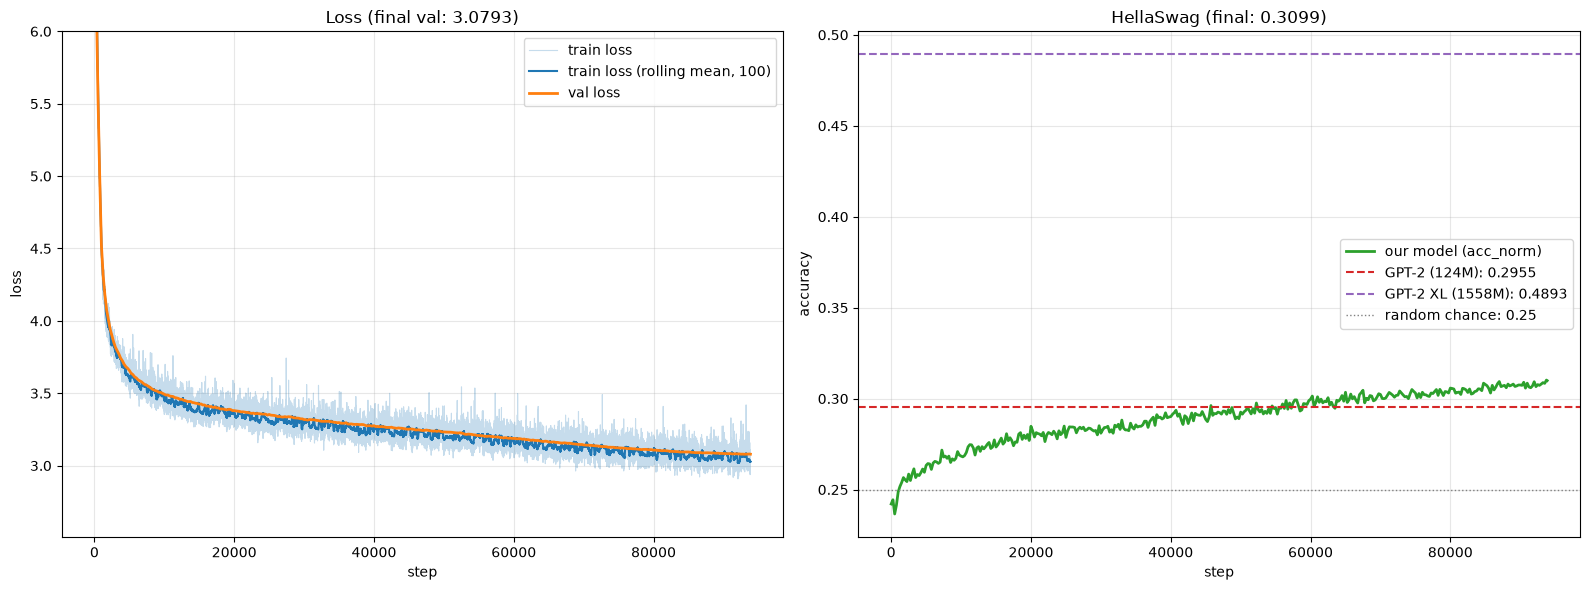

In [2]:
# HellaSwag baselines from hellaswag.py (completion-style eval of the OpenAI checkpoints)
# acc_norm values, matching the metric logged by train_gpt2.py
baselines = {
    "GPT-2 (124M)": 0.2955,
    "GPT-2 XL (1558M)": 0.4893,
}

smooth = 100  # rolling window for the (noisy) per-step train loss

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. train / val loss
ax1.plot(train.index, train.values, color="tab:blue", alpha=0.25, lw=0.8, label="train loss")
ax1.plot(train.index, train.rolling(smooth, min_periods=1).mean(), color="tab:blue", lw=1.5,
         label=f"train loss (rolling mean, {smooth})")
ax1.plot(val.index, val.values, color="tab:orange", lw=2, label="val loss")
ax1.set_xlabel("step")
ax1.set_ylabel("loss")
ax1.set_ylim(top=min(6.0, train.max()))
ax1.set_title(f"Loss (final val: {val.iloc[-1]:.4f})")
ax1.grid(alpha=0.3)
ax1.legend()

# 2. HellaSwag accuracy
ax2.plot(hella.index, hella.values, color="tab:green", lw=2, label="our model (acc_norm)")
for (name, acc), color in zip(baselines.items(), ["tab:red", "tab:purple"]):
    ax2.axhline(acc, color=color, ls="--", lw=1.5, label=f"{name}: {acc:.4f}")
ax2.axhline(0.25, color="gray", ls=":", lw=1, label="random chance: 0.25")
ax2.set_xlabel("step")
ax2.set_ylabel("accuracy")
ax2.set_title(f"HellaSwag (final: {hella.iloc[-1]:.4f})")
ax2.grid(alpha=0.3)
ax2.legend()

plt.tight_layout()
plt.show()